# Forecasting the Ibovespa closing index
FIAP postgraduate program in Data Analytics · Tech Challenge 2

How much does a forecasting model improve on carrying the last known close forward? This study compares three baselines on the same 30 trading sessions, then examines what ARIMA, Prophet and XGBoost can tell us under the evaluation designs used in the original project.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import xgboost as xgb

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf as _plot_acf
from statsmodels.graphics.tsaplots import plot_pacf as _plot_pacf

from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

import warnings
from pandas.errors import SettingWithCopyWarning
warnings.simplefilter(action="ignore", category=SettingWithCopyWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore")
sns.set_style("darkgrid")

In [2]:
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return mae, mse, mape

def metrics_to_df(metrics, model_name):
    mae, mse, mape = metrics

    return pd.DataFrame(
        {
            "MAE": [mae],
            "MSE": [mse],
            "MAPE (%)": [mape],
        },
        index=[model_name]
    )

def plot_acf(data, lags=365, title="Autocorrelation of the closing index"):
    fig, ax = plt.subplots(figsize=(15, 5))

    _plot_acf(data, lags=lags, ax=ax, alpha=0.05)
    ax.set_title(title)
    ax.set_xlabel("Lags")
    ax.set_ylabel("Autocorrelation")
    fig.set_tight_layout(True)

    acf_x = sm.tsa.acf(data, alpha=0.05, nlags=lags)
    acf, ci = acf_x[:2]
    intercept_point = np.where(abs(acf) < (ci[:, 1] - acf))
    if intercept_point[0].size > 0:
        print(
            f"The ACF coefficients intercept the threshold at lag {intercept_point[0][0]}"
        )
    else:
        print("The ACF coefficients do not intercept the threshold")

def plot_pacf(data, lags=30, title="Partial autocorrelation of the closing index"):
    fig, ax = plt.subplots(figsize=(15, 5))

    _plot_pacf(data, lags=lags, ax=ax, alpha=0.05)
    ax.set_title(title)
    ax.set_xlabel("Lags")
    ax.set_ylabel("Partial autocorrelation")
    fig.set_tight_layout(True)

    acf_x = sm.tsa.pacf(data, alpha=0.05, nlags=lags)
    acf, ci = acf_x[:2]
    intercept_point = np.where(abs(acf) < (ci[:, 1] - acf))
    if intercept_point[0].size > 0:
        print(
            f"The PACF coefficients intercept the threshold at lag {intercept_point[0][0]}"
        )
    else:
        print("The PACF coefficients do not intercept the threshold")

## 1. Historical data
The daily Investing.com export contains 2,729 sessions, from January 2, 2015 through December 30, 2025. The source provides the date, open, high, low, close, volume and percentage change. This experiment uses the opening and closing levels in thousands of index points.

In [3]:
from pathlib import Path

data_dir = Path("data") if Path("data").is_dir() else Path("../data")
df = pd.read_csv(data_dir / "ibovespa.csv", dtype=str)
print(f"{len(df):,} observations")

2,729 observations


The loader accepts the original provider headers and a standardized English file. The guide in the data directory describes both formats.

In [4]:
df.columns = df.columns.str.strip().str.lower()
provider_format = {"data", "abertura", "último"}.issubset(df.columns)
if provider_format:
    df = df.rename(columns={"data": "date", "abertura": "open", "último": "close"})
date_format = "%d.%m.%Y" if provider_format else "%Y-%m-%d"
df = df[["date", "open", "close"]].copy()
df["date"] = pd.to_datetime(df["date"], format=date_format)
df[["open", "close"]] = df[["open", "close"]].apply(pd.to_numeric)
df = df.sort_values("date").reset_index(drop=True)
print(f"Date range: {df.date.min().date()} to {df.date.max().date()}")
print("Missing values by field:")
print(df.isna().sum())

Date range: 2015-01-02 to 2025-12-30
Missing values by field:
date     0
open     0
close    0
dtype: int64


## 2. Exploring the series
The closing series exhibits a long-term trend and periods of increased volatility. Additive decomposition with a period of 365 observations separates trend, a relatively weak seasonal component and substantial short-term variation. Decomposition and price-history plots can be reproduced with a local copy of the data.

In [5]:
sd = seasonal_decompose(df["close"], model="additive", period=365)
fig, (ax1,ax2,ax3,ax4) = plt.subplots(4,1, figsize = (15, 15))

sd.observed.plot(ax=ax1, title="Observed closing index")
sd.trend.plot(ax=ax2, color="g", title="Trend")
sd.seasonal.plot(ax=ax3, color="#631914", title="Seasonal component")
sd.resid.plot(ax=ax4, color="#7c822c", title="Residuals")

plt.tight_layout()

The autocorrelation (ACF) and partial autocorrelation (PACF) plots examine how the closing index relates to its previous values.

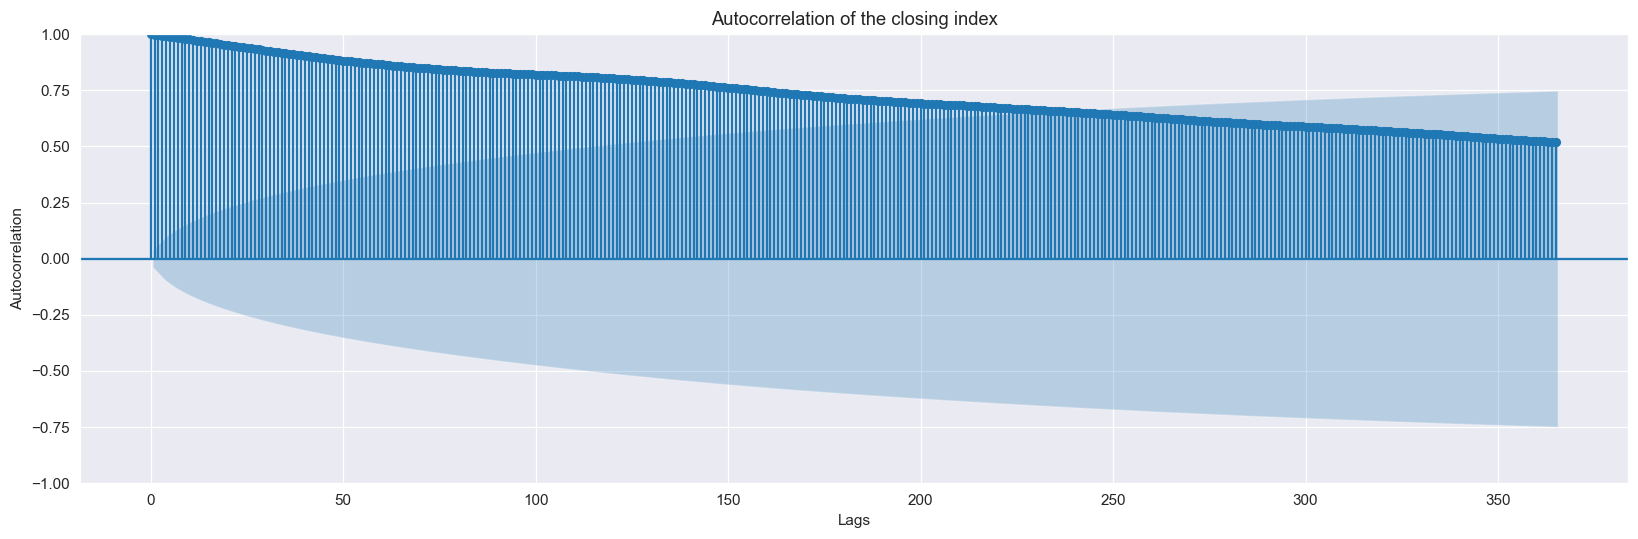

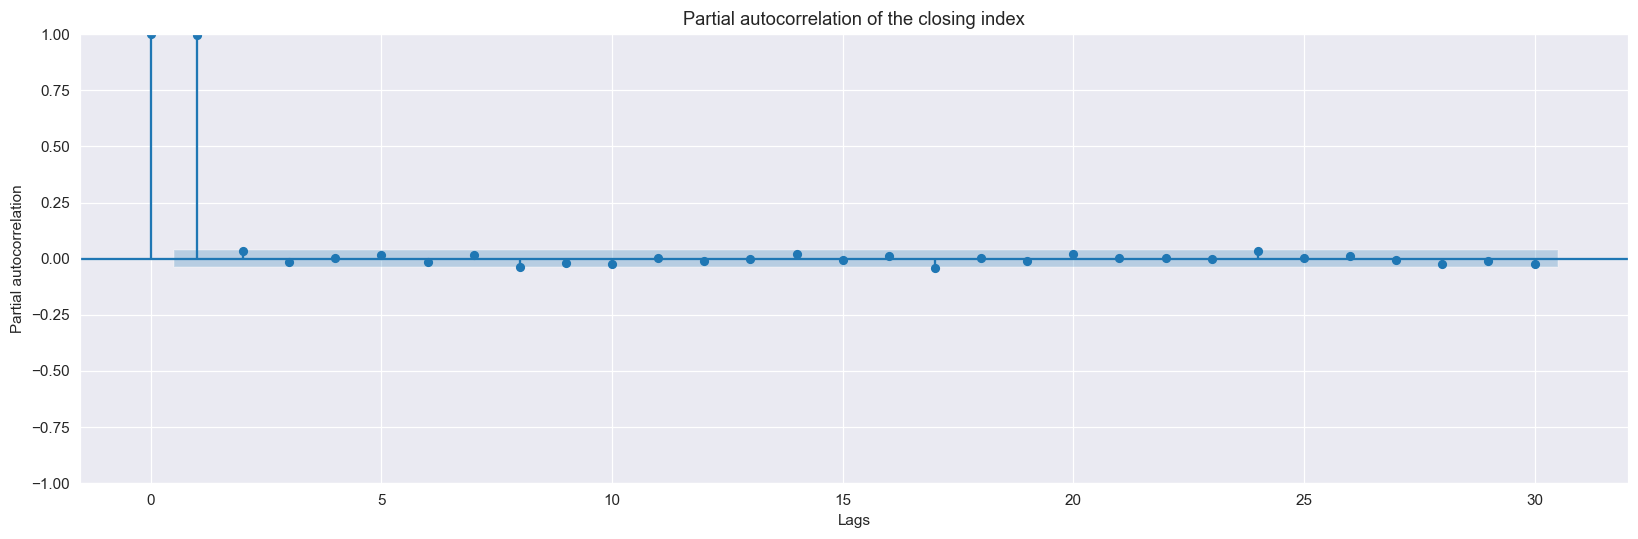

In [6]:
fig, ax = plt.subplots(figsize=(15, 5))
_plot_acf(df["close"], lags=365, ax=ax, alpha=0.05)
ax.set_title("Autocorrelation of the closing index")
ax.set_xlabel("Lags")
ax.set_ylabel("Autocorrelation")
fig.set_tight_layout(True)


fig, ax = plt.subplots(figsize=(15, 5))
_plot_pacf(df["close"], lags=30, ax=ax, alpha=0.05)
ax.set_title("Partial autocorrelation of the closing index")
ax.set_xlabel("Lags")
ax.set_ylabel("Partial autocorrelation")
fig.set_tight_layout(True)

The augmented Dickey–Fuller test on the levels does not reject the unit-root null hypothesis at the 5% level.

In [7]:
def unit_root_test(series, label):
    statistic, p_value, _, _, critical, _ = adfuller(series.dropna())
    print(label)
    print(f"Test statistic: {statistic:.5f}; p-value: {p_value:.5g}")
    print("Critical values:", {level: round(value, 3) for level, value in critical.items()})
    print("Reject the unit-root null." if p_value < 0.05 else "Cannot reject the unit-root null.")

unit_root_test(df["close"], "Augmented Dickey–Fuller test on closing levels")
df.set_index("date")["close"].plot(title="Daily closing index", xlabel="Date", ylabel="Thousands of index points")
plt.tight_layout()

Augmented Dickey–Fuller test on closing levels
Test statistic: -0.80435; p-value: 0.81784
Critical values: {'1%': -3.433, '5%': -2.863, '10%': -2.567}
Cannot reject the unit-root null.


## 3. Feature engineering
First differences remove much of the trend. We repeat the unit-root test on the differences and use their ACF and PACF to choose candidate ARIMA orders. The boosted-tree experiment adds calendar features, the close-to-close change and the return relative to the open.

Augmented Dickey–Fuller test on first differences
Test statistic: -16.86281; p-value: 1.0963e-29
Critical values: {'1%': -3.433, '5%': -2.863, '10%': -2.567}
Reject the unit-root null.


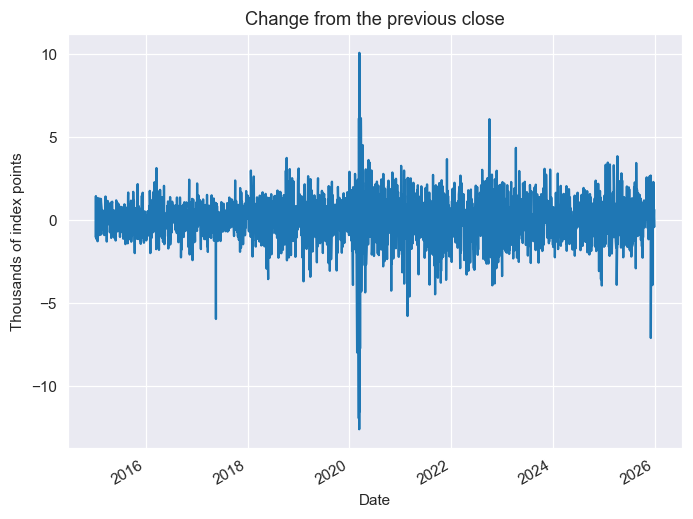

In [8]:
changes = df.set_index("date")["close"].diff().dropna()
unit_root_test(changes, "Augmented Dickey–Fuller test on first differences")
changes.plot(title="Change from the previous close", xlabel="Date", ylabel="Thousands of index points")
plt.tight_layout()

In [9]:
df_diff = df["close"].diff().dropna()


acf_x = sm.tsa.acf(df_diff, alpha=0.05, nlags=30)
acf, ci = acf_x[:2]
q = np.where(abs(acf) < (ci[:, 1] - acf))[0][0]

pacf_x = sm.tsa.pacf(df_diff, alpha=0.05, nlags=30)
pacf, ci = pacf_x[:2]
p = np.where(abs(pacf) < (ci[:, 1] - pacf))[0][0]

d = 1

## 4. Training and evaluation windows
The baselines, ARIMA and Prophet use the first 2,699 sessions to fit their forecasts and the final 30 closes to calculate errors. ARIMA order selection uses the full series. Prophet receives the observed test-period opening values and predicts consecutive calendar days.

In the original XGBoost experiment, training and evaluation use the same rows. Two features shift next-session changes and returns backwards into the current row. Its error therefore measures fit to data that include future information.

In [10]:
train_size = df.shape[0] - 30
train, test = df[:train_size], df[train_size:]


df_xgboost = df.copy()
df_xgboost["date"] = pd.to_datetime(df["date"])
df_xgboost["year"] = df["date"].dt.year
df_xgboost["month"] = df["date"].dt.month
df_xgboost["day"] = df["date"].dt.day
df_xgboost["dayofweek"] = df["date"].dt.dayofweek
df_xgboost["delta"] = df["close"].diff().shift(-1)
df_xgboost["daily_return"] = ((df["close"] - df["open"]) / df["open"]).shift(-1)
xgb_train = df_xgboost
xgb_test = df_xgboost

FEATURES = ["year", "month", "day", "dayofweek", "open", "delta", "daily_return"]
TARGET = "close"

## 5. Forecasting models
The naive baseline repeats the final training close. Seasonal naive repeats the last five sessions. The seasonal window average averages the two latest five-session cycles by position. ARIMA models the autocorrelation after differencing. Prophet models trend and seasonality with the opening level as a regressor. XGBoost fits a nonlinear relationship between the closing level and the engineered features.

In [11]:
y_train = train.set_index("date")["close"]
y_test  = test.set_index("date")["close"]

h = len(y_test)


last_value = y_train.iloc[-1]

naive_preds = pd.Series(
    data=[last_value] * h,
    index=y_test.index
)

df_naive = metrics_to_df(
    calculate_metrics(y_test, naive_preds),
    model_name="Naive"
)

In [12]:
season_length = 5

seasonal_naive_preds = y_train.iloc[-season_length:].values
seasonal_naive_preds = np.tile(
    seasonal_naive_preds,
    int(np.ceil(h / season_length))
)[:h]

seasonal_naive_preds = pd.Series(
    seasonal_naive_preds,
    index=y_test.index
)

df_seasonal = metrics_to_df(
    calculate_metrics(y_test, seasonal_naive_preds),
    model_name="Seasonal Naive"
)

In [13]:
k = 2
season_length = 5

window = y_train.iloc[-k * season_length:]
window_avg = window.values.reshape(k, season_length).mean(axis=0)

seasonal_window_avg_preds = np.tile(
    window_avg,
    int(np.ceil(h / season_length))
)[:h]

seasonal_window_avg_preds = pd.Series(
    seasonal_window_avg_preds,
    index=y_test.index
)

df_window_avg = metrics_to_df(
    calculate_metrics(y_test, seasonal_window_avg_preds),
    model_name="Seasonal Window Avg"
)

In [14]:
arima_model = ARIMA(
    y_train,
    order=(p, d, q)
)

arima_fit = arima_model.fit()
arima_preds = arima_fit.forecast(steps=h)
arima_preds.index = y_test.index

df_arima = metrics_to_df(
    calculate_metrics(y_test, arima_preds),
    model_name="ARIMA"
)

In [15]:
train_prophet = train.rename(columns={"date": "ds", "close": "y"})
test_prophet = test.rename(columns={"date": "ds", "close": "y"})

model = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
model.add_regressor("open")
model.fit(train_prophet)

future = model.make_future_dataframe(periods=len(test))
future["open"] = pd.concat([train["open"], test["open"]], ignore_index=True)
forecast = model.predict(future)

prophet_preds = forecast[["ds", "yhat"]].tail(len(test))
prophet_preds = prophet_preds.set_index("ds")
y_test = test_prophet.set_index("ds")["y"]

df_prophet = metrics_to_df(
    calculate_metrics(y_test, prophet_preds["yhat"]),
    model_name="Prophet"
)

In [16]:
X_train, y_train = xgb_train[FEATURES], xgb_train[TARGET]
X_test, y_test = xgb_test[FEATURES], xgb_test[TARGET]

reg = xgb.XGBRegressor(objective="reg:squarederror")
reg.fit(X_train, y_train)
xgb_preds = reg.predict(X_test)

df_xgboost = metrics_to_df(
    calculate_metrics(y_test, xgb_preds),
    model_name="XGBoost"
)

## 6. Forecast errors
Mean absolute error (MAE) is in thousands of index points. Mean squared error (MSE) uses squared units. Mean absolute percentage error (MAPE) expresses the average absolute error relative to the observed close.

In [17]:
results_df = pd.concat([
    df_naive,
    df_seasonal,
    df_window_avg,
    df_arima,
    df_prophet,
    df_xgboost
])

results_df.sort_values("MAPE (%)")

,MAE,MSE,MAPE (%)
XGBoost,0.313553,0.182954,0.354880
ARIMA,2.108007,7.201259,1.316630
Naive,2.144333,7.378130,1.339267
Seasonal Naive,2.811667,11.860292,1.759395
Prophet,3.006000,15.693661,1.894778
Seasonal Window Avg,4.883067,29.572904,3.059180


Only the three baselines share both the evaluation window and a strict information cutoff. Their MAPEs are 1.34% for naive, 1.76% for seasonal naive and 3.06% for the seasonal window average. Prophet compares its calendar-day forecasts with trading sessions by position. ARIMA selected its orders using the complete history. The XGBoost figure is an in-sample score with next-session information.

## 7. Five-weekday scenario
The original experiment fits XGBoost to the full history, holds the last opening level fixed and sets the unknown price change and daily return to zero. Each arrow compares two consecutive projections. The pandas weekday calendar can include exchange holidays.

In [18]:
X_full = xgb_train[FEATURES]
y_full = xgb_train[TARGET]

reg = xgb.XGBRegressor(objective="reg:squarederror", random_state=42)
reg.fit(X_full, y_full)

h = 5
last_date = df["date"].iloc[-1]

future_dates = pd.bdate_range(
    start=last_date + pd.Timedelta(days=1),
    periods=h
)

last_row = xgb_train.iloc[-1]
future_df = pd.DataFrame({
    "year": future_dates.year,
    "month": future_dates.month,
    "day": future_dates.day,
    "dayofweek": future_dates.dayofweek,
    "open": last_row["open"],
    "delta": 0,
    "daily_return": 0
})

future_forecast = reg.predict(future_df)

In [19]:
plt.figure(figsize=(14, 6))


plt.plot(
    df["date"].iloc[-360:],
    df["close"].iloc[-360:],
    label="Historical close"
)


plt.plot(
    future_dates,
    future_forecast,
    label="XGBoost scenario",
    linestyle="--"
)

plt.title("Ibovespa five-weekday XGBoost scenario")
plt.xlabel("Date")
plt.ylabel("Closing index")
plt.legend()
plt.show()

In [20]:
forecast_df = pd.DataFrame({"Date": future_dates, "Projected close": future_forecast})
change = forecast_df["Projected close"].diff()
forecast_df["Direction"] = np.select([change.gt(0), change.lt(0)], ["↑", "↓"], default="–")
forecast_df["Projected close"] = forecast_df["Projected close"].round(3)
final_output = forecast_df.set_index("Date")
final_output

,Projected close,Direction
Date,,
2025-12-31,159.854004,–
2026-01-01,152.257004,↓
2026-01-02,153.863007,↑
2026-01-05,151.462006,↓
2026-01-06,152.195007,↑


## 8. Interpretation
XGBoost can represent nonlinear relationships between calendar features, the open and the close. Estimating its future accuracy would require features available at forecast time and a separate chronological holdout. The three baselines use only closes known at the forecast origin.

## 9. Conclusion
Repeating the November 13, 2025 close produced the smallest percentage error among the three baselines over the following 30 trading sessions. A common cutoff and the same tradable dates would make a future comparison with the more complex models meaningful.